In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from pathlib import Path

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)

OpenCV: 4.11.0
NumPy: 1.26.4


In [2]:
DATASET_DIR = Path(
    r"C:\Users\Korisnik\Desktop\PASSTA_dataset\PASSTA_dataset\LunchRoom\LunchRoom"
)

print("Folder postoji:", DATASET_DIR.exists())

Folder postoji: True


In [3]:
image_paths = sorted(
    DATASET_DIR.glob("img*.jpg")
)

print("Broj slika:", len(image_paths))

for path in image_paths[:10]:
    print(path.name)

Broj slika: 72
img01.jpg
img02.jpg
img03.jpg
img04.jpg
img05.jpg
img06.jpg
img07.jpg
img08.jpg
img09.jpg
img10.jpg


In [4]:
def load_image(path):
    image = cv2.imread(str(path))

    if image is None:
        raise ValueError(
            f"Ne mogu učitati: {path}"
        )

    return cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )


images = [
    load_image(path)
    for path in image_paths
]

print("Učitano:", len(images))

Učitano: 72


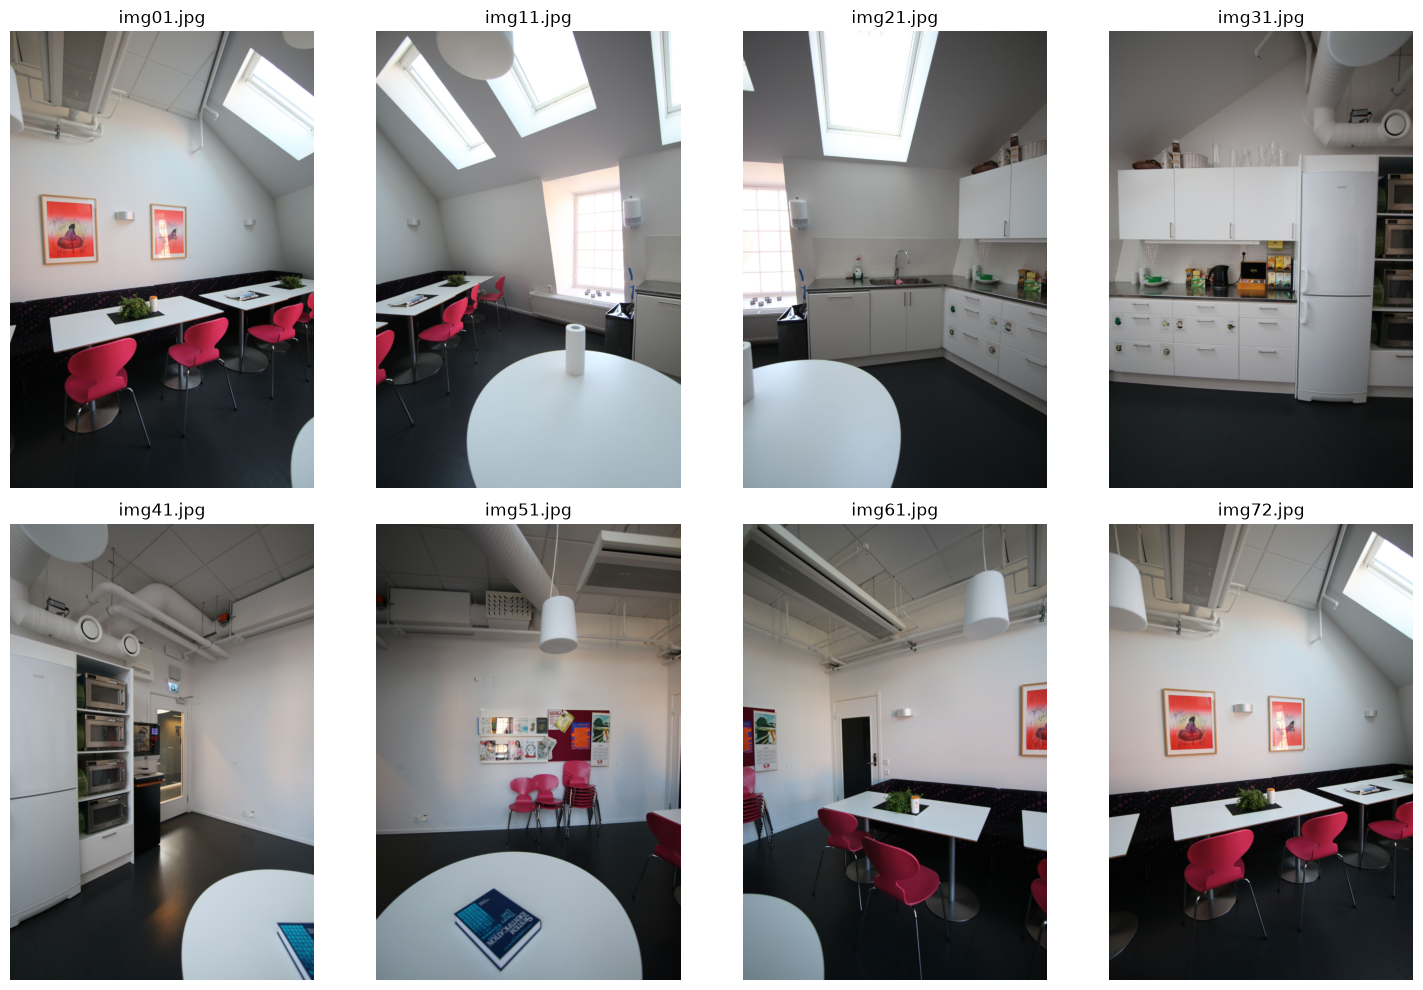

In [5]:
plt.figure(figsize=(15, 10))

indices = [0, 10, 20, 30, 40, 50, 60, 71]

for i, idx in enumerate(indices):

    plt.subplot(2, 4, i + 1)
    plt.imshow(images[idx])
    plt.title(image_paths[idx].name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
MAX_WIDTH = 1200


def resize_image(image, max_width=MAX_WIDTH):

    h, w = image.shape[:2]

    if w <= max_width:
        return image

    scale = max_width / w

    new_size = (
        int(w * scale),
        int(h * scale)
    )

    return cv2.resize(
        image,
        new_size,
        interpolation=cv2.INTER_AREA
    )


images = [
    resize_image(image)
    for image in images
]

print(
    "Dimenzije prve slike:",
    images[0].shape
)

Dimenzije prve slike: (1800, 1200, 3)


In [7]:
START = 0
END = 8

selected_images = images[
    START:END
]

selected_paths = image_paths[
    START:END
]

print(
    "Broj odabranih fotografija:",
    len(selected_images)
)

for path in selected_paths:
    print(path.name)

Broj odabranih fotografija: 8
img01.jpg
img02.jpg
img03.jpg
img04.jpg
img05.jpg
img06.jpg
img07.jpg
img08.jpg


In [8]:
sift = cv2.SIFT_create(
    nfeatures=5000
)

In [9]:
keypoints = []
descriptors = []

for image in selected_images:

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2GRAY
    )

    kp, des = sift.detectAndCompute(
        gray,
        None
    )

    keypoints.append(kp)
    descriptors.append(des)

for i, kp in enumerate(keypoints):

    print(
        f"{selected_paths[i].name}: "
        f"{len(kp)} značajki"
    )



img01.jpg: 1061 značajki
img02.jpg: 1097 značajki
img03.jpg: 1029 značajki
img04.jpg: 935 značajki
img05.jpg: 907 značajki
img06.jpg: 839 značajki
img07.jpg: 726 značajki
img08.jpg: 766 značajki


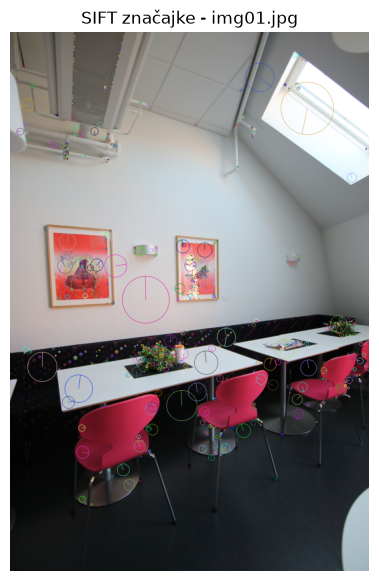

In [10]:
idx = 0

output = cv2.drawKeypoints(
    selected_images[idx],
    keypoints[idx],
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

plt.figure(figsize=(14, 7))
plt.imshow(output)
plt.title(
    f"SIFT značajke - {selected_paths[idx].name}"
)
plt.axis("off")
plt.show()

In [11]:
FLANN_INDEX_KDTREE = 1

index_params = {
    "algorithm": FLANN_INDEX_KDTREE,
    "trees": 5
}

search_params = {
    "checks": 50
}

flann = cv2.FlannBasedMatcher(
    index_params,
    search_params
)

In [12]:
def match_features(
    des1,
    des2,
    ratio=0.75
):

    matches = flann.knnMatch(
        des1,
        des2,
        k=2
    )

    good = []

    for pair in matches:

        if len(pair) < 2:
            continue

        m, n = pair

        if m.distance < ratio * n.distance:
            good.append(m)

    return good

In [13]:
pair_matches = []

for i in range(
    len(selected_images) - 1
):

    matches = match_features(
        descriptors[i],
        descriptors[i + 1]
    )

    pair_matches.append(matches)

    print(
        f"{selected_paths[i].name} -> "
        f"{selected_paths[i+1].name}: "
        f"{len(matches)} podudaranja"
    )

img01.jpg -> img02.jpg: 747 podudaranja
img02.jpg -> img03.jpg: 717 podudaranja
img03.jpg -> img04.jpg: 658 podudaranja
img04.jpg -> img05.jpg: 659 podudaranja
img05.jpg -> img06.jpg: 597 podudaranja
img06.jpg -> img07.jpg: 480 podudaranja
img07.jpg -> img08.jpg: 440 podudaranja


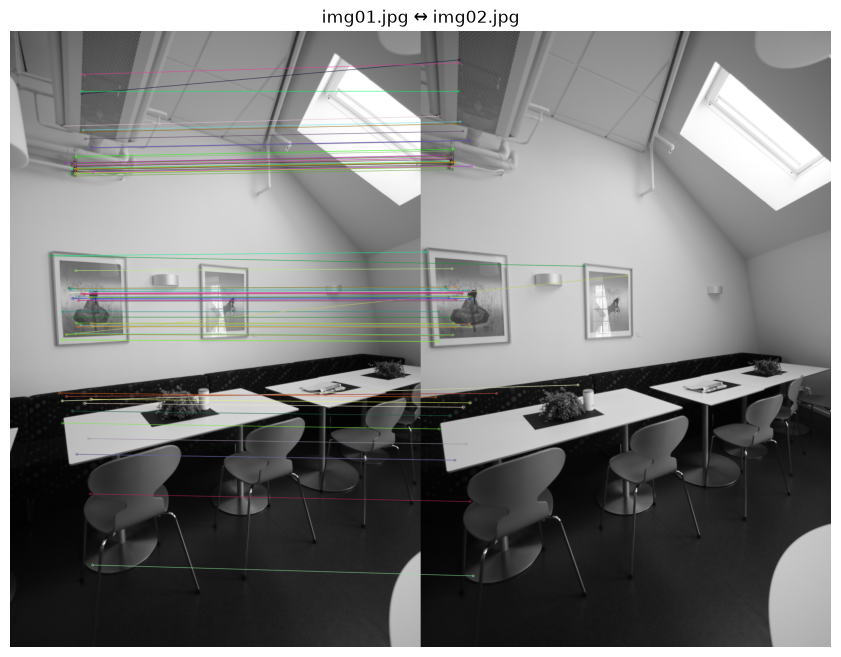

In [14]:
i = 0

img1_gray = cv2.cvtColor(
    selected_images[i],
    cv2.COLOR_RGB2GRAY
)

img2_gray = cv2.cvtColor(
    selected_images[i + 1],
    cv2.COLOR_RGB2GRAY
)

matches_to_show = pair_matches[i][:80]

result = cv2.drawMatches(
    img1_gray,
    keypoints[i],
    img2_gray,
    keypoints[i + 1],
    matches_to_show,
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(18, 8))
plt.imshow(result, cmap="gray")
plt.title(
    f"{selected_paths[i].name} ↔ "
    f"{selected_paths[i+1].name}"
)
plt.axis("off")
plt.show()

In [15]:
def estimate_homography(
    kp1,
    kp2,
    matches
):

    if len(matches) < 4:
        return None, None

    src_pts = np.float32([
        kp1[m.queryIdx].pt
        for m in matches
    ]).reshape(-1, 1, 2)

    dst_pts = np.float32([
        kp2[m.trainIdx].pt
        for m in matches
    ]).reshape(-1, 1, 2)

    H, mask = cv2.findHomography(
        src_pts,
        dst_pts,
        cv2.RANSAC,
        5.0
    )

    if H is None:
        return None, None

    return H, mask.ravel().astype(bool)

In [16]:
homographies = []
inlier_masks = []

for i, matches in enumerate(pair_matches):

    H, mask = estimate_homography(
        keypoints[i],
        keypoints[i + 1],
        matches
    )

    homographies.append(H)
    inlier_masks.append(mask)

    print(
        f"\n{selected_paths[i].name} -> "
        f"{selected_paths[i+1].name}"
    )

    if H is None:

        print("Homografija nije pronađena.")
        continue

    print(
        "Broj inliera:",
        np.sum(mask),
        "/",
        len(mask)
    )

    print("H =")
    print(H)


img01.jpg -> img02.jpg
Broj inliera: 688 / 747
H =
[[ 1.12657730e+00  5.15766309e-03 -1.24559220e+02]
 [ 8.71206398e-02  1.06619737e+00 -5.56538240e+01]
 [ 1.03985975e-04 -8.14133189e-07  1.00000000e+00]]

img02.jpg -> img03.jpg
Broj inliera: 675 / 717
H =
[[ 1.12155056e+00  5.30886960e-03 -1.19494375e+02]
 [ 8.33226798e-02  1.06370026e+00 -5.34843683e+01]
 [ 9.97392592e-05 -5.62872665e-07  1.00000000e+00]]

img03.jpg -> img04.jpg
Broj inliera: 615 / 658
H =
[[ 1.15231657e+00  6.34928840e-03 -1.47700078e+02]
 [ 1.04462931e-01  1.08165043e+00 -6.77895041e+01]
 [ 1.24646832e-04 -1.23602373e-07  1.00000000e+00]]

img04.jpg -> img05.jpg
Broj inliera: 592 / 659
H =
[[ 1.09303955e+00  4.82256024e-03 -9.25398249e+01]
 [ 6.31901403e-02  1.04920526e+00 -4.06846542e+01]
 [ 7.58871707e-05  5.43746485e-08  1.00000000e+00]]

img05.jpg -> img06.jpg
Broj inliera: 567 / 597
H =
[[ 1.12402580e+00  5.66453781e-03 -1.22241478e+02]
 [ 8.52847409e-02  1.06560790e+00 -5.47027498e+01]
 [ 1.02010603e-04 -3.8

In [17]:
def reprojection_error(
    kp1,
    kp2,
    matches,
    H,
    mask
):

    src = np.float32([
        kp1[m.queryIdx].pt
        for m in matches
    ]).reshape(-1, 1, 2)

    dst = np.float32([
        kp2[m.trainIdx].pt
        for m in matches
    ]).reshape(-1, 1, 2)

    projected = cv2.perspectiveTransform(
        src,
        H
    )

    errors = np.linalg.norm(
        projected.reshape(-1, 2)
        -
        dst.reshape(-1, 2),
        axis=1
    )

    return errors[mask]

In [18]:
results = []

for i, H in enumerate(homographies):

    if H is None:
        continue

    errors = reprojection_error(
        keypoints[i],
        keypoints[i + 1],
        pair_matches[i],
        H,
        inlier_masks[i]
    )

    total = len(
        pair_matches[i]
    )

    inliers = np.sum(
        inlier_masks[i]
    )

    results.append({
        "Par":
            f"{selected_paths[i].name} - "
            f"{selected_paths[i+1].name}",

        "Matches":
            total,

        "Inliers":
            int(inliers),

        "Inlier ratio":
            inliers / total,

        "Mean error (px)":
            np.mean(errors),

        "Median error (px)":
            np.median(errors),

        "Max error (px)":
            np.max(errors)
    })


evaluation_df = pd.DataFrame(results)

evaluation_df

,Par,Matches,Inliers,Inlier ratio,Mean error (px),Median error (px),Max error (px)
0,img01.jpg - img02.jpg,747,688,0.921017,0.475194,0.303662,7.432321
1,img02.jpg - img03.jpg,717,675,0.941423,0.466745,0.305285,6.763913
2,img03.jpg - img04.jpg,658,615,0.934650,0.482565,0.341188,6.095158
3,img04.jpg - img05.jpg,659,592,0.898331,0.318359,0.219184,4.060255
4,img05.jpg - img06.jpg,597,567,0.949749,0.431071,0.293185,4.157000
5,img06.jpg - img07.jpg,480,446,0.929167,0.422897,0.282338,3.997988
6,img07.jpg - img08.jpg,440,405,0.920455,0.525337,0.354475,5.520755


In [19]:
def warp_two_images(
    image1,
    image2,
    H
):

    h1, w1 = image1.shape[:2]
    h2, w2 = image2.shape[:2]

    corners1 = np.float32([
        [0, 0],
        [w1, 0],
        [w1, h1],
        [0, h1]
    ]).reshape(-1, 1, 2)

    corners2 = np.float32([
        [0, 0],
        [w2, 0],
        [w2, h2],
        [0, h2]
    ]).reshape(-1, 1, 2)

    transformed = cv2.perspectiveTransform(
        corners1,
        H
    )

    all_corners = np.concatenate(
        [transformed, corners2],
        axis=0
    )

    xmin, ymin = np.floor(
        all_corners.min(axis=0).ravel()
    ).astype(int)

    xmax, ymax = np.ceil(
        all_corners.max(axis=0).ravel()
    ).astype(int)

    tx = -xmin
    ty = -ymin

    T = np.array([
        [1, 0, tx],
        [0, 1, ty],
        [0, 0, 1]
    ], dtype=np.float64)

    width = xmax - xmin
    height = ymax - ymin

    warped1 = cv2.warpPerspective(
        image1,
        T @ H,
        (width, height)
    )

    warped2 = np.zeros_like(
        warped1
    )

    warped2[
        ty:ty+h2,
        tx:tx+w2
    ] = image2

    return warped1, warped2

In [20]:
def feather_blend(
    image1,
    image2
):

    gray1 = cv2.cvtColor(
        image1,
        cv2.COLOR_RGB2GRAY
    )

    gray2 = cv2.cvtColor(
        image2,
        cv2.COLOR_RGB2GRAY
    )

    mask1 = (
        gray1 > 0
    ).astype(np.uint8) * 255

    mask2 = (
        gray2 > 0
    ).astype(np.uint8) * 255

    dist1 = cv2.distanceTransform(
        mask1,
        cv2.DIST_L2,
        5
    )

    dist2 = cv2.distanceTransform(
        mask2,
        cv2.DIST_L2,
        5
    )

    total = dist1 + dist2 + 1e-8

    w1 = dist1 / total
    w2 = dist2 / total

    result = (
        image1.astype(np.float32) *
        w1[..., None]
        +
        image2.astype(np.float32) *
        w2[..., None]
    )

    return np.clip(
        result,
        0,
        255
    ).astype(np.uint8)



In [21]:
def stitch_pair(
    image1,
    image2
):

    gray1 = cv2.cvtColor(
        image1,
        cv2.COLOR_RGB2GRAY
    )

    gray2 = cv2.cvtColor(
        image2,
        cv2.COLOR_RGB2GRAY
    )

    sift = cv2.SIFT_create(
        nfeatures=5000
    )

    kp1, des1 = sift.detectAndCompute(
        gray1,
        None
    )

    kp2, des2 = sift.detectAndCompute(
        gray2,
        None
    )

    matches = match_features(
        des1,
        des2
    )

    if len(matches) < 4:

        raise ValueError(
            "Nema dovoljno podudaranja."
        )

    src = np.float32([
        kp1[m.queryIdx].pt
        for m in matches
    ]).reshape(-1, 1, 2)

    dst = np.float32([
        kp2[m.trainIdx].pt
        for m in matches
    ]).reshape(-1, 1, 2)

    H, mask = cv2.findHomography(
        src,
        dst,
        cv2.RANSAC,
        5.0
    )

    if H is None:

        raise ValueError(
            "Homografija nije pronađena."
        )

    warped1, warped2 = warp_two_images(
        image1,
        image2,
        H
    )

    result = feather_blend(
        warped1,
        warped2
    )

    return result

In [22]:
panorama = selected_images[0]

for i in range(
    1,
    len(selected_images)
):

    print(
        f"Spajam {i+1}/"
        f"{len(selected_images)}..."
    )

    panorama = stitch_pair(
        panorama,
        selected_images[i]
    )

    print("Gotovo.")

Spajam 2/8...
Gotovo.
Spajam 3/8...
Gotovo.
Spajam 4/8...
Gotovo.
Spajam 5/8...
Gotovo.
Spajam 6/8...
Gotovo.
Spajam 7/8...
Gotovo.
Spajam 8/8...
Gotovo.


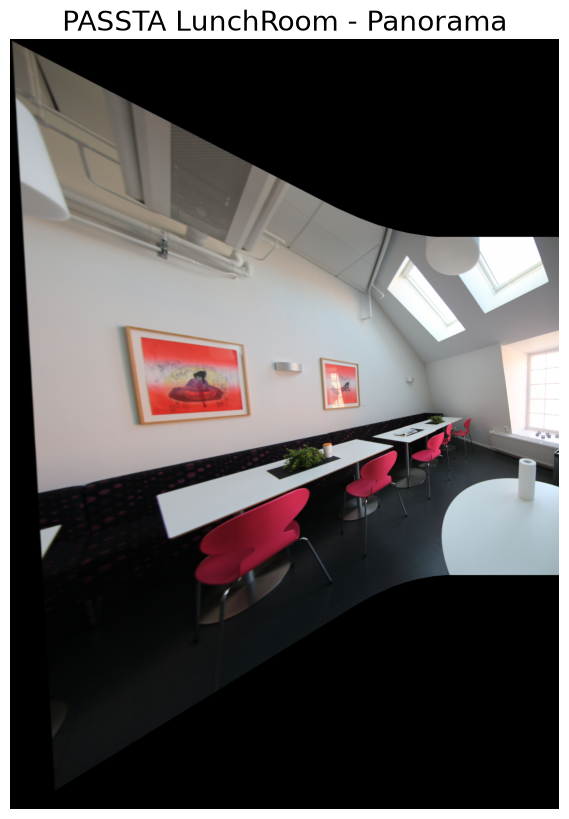

In [23]:
plt.figure(
    figsize=(24, 10)
)

plt.imshow(panorama)

plt.title(
    "PASSTA LunchRoom - Panorama",
    fontsize=20
)

plt.axis("off")

plt.show()

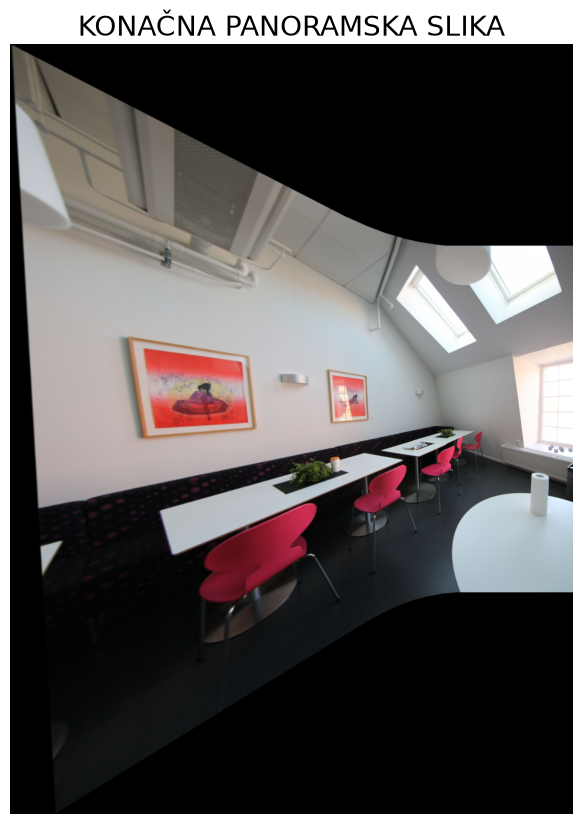

In [24]:
def crop_black_borders(image):

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2GRAY
    )

    mask = gray > 0

    coords = np.argwhere(mask)

    if len(coords) == 0:
        return image

    y_min, x_min = coords.min(axis=0)
    y_max, x_max = coords.max(axis=0)

    return image[
        y_min:y_max+1,
        x_min:x_max+1
    ]

final_panorama = crop_black_borders(
    panorama
)

plt.figure(
    figsize=(24, 10)
)

plt.imshow(final_panorama)

plt.title(
    "KONAČNA PANORAMSKA SLIKA",
    fontsize=20
)

plt.axis("off")

plt.show()

In [25]:
OUTPUT_PATH = (
    DATASET_DIR /
    "PASSTA_LunchRoom_panorama.jpg"
)

cv2.imwrite(
    str(OUTPUT_PATH),
    cv2.cvtColor(
        final_panorama,
        cv2.COLOR_RGB2BGR
    )
)

print(
    "Panorama spremljena u:"
)

print(OUTPUT_PATH)

Panorama spremljena u:
C:\Users\Korisnik\Desktop\PASSTA_dataset\PASSTA_dataset\LunchRoom\LunchRoom\PASSTA_LunchRoom_panorama.jpg


In [26]:
EVALUATION_PATH = (
    DATASET_DIR /
    "registration_evaluation.csv"
)

evaluation_df.to_csv(
    EVALUATION_PATH,
    index=False
)

print(
    "Evaluacija spremljena u:"
)

print(EVALUATION_PATH)

Evaluacija spremljena u:
C:\Users\Korisnik\Desktop\PASSTA_dataset\PASSTA_dataset\LunchRoom\LunchRoom\registration_evaluation.csv
